In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


importación de librerías para evaluar el modelo, creación de matriz de confusión

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)
import matplotlib.pyplot as plt

# importa herramientas para crear un modelo de red neuronal y para visualizar los resultados


**Cargar el conjunto de datos**


In [5]:
# El archivo debe estar en el mismo directorio
data = pd.read_csv("../data/pima-indians-diabetes.csv", header=None)

# Separar variables de entrada y salida
X = data.iloc[:, 0:8].values
y = data.iloc[:, 8].values

# ==========================================
# Normalizar los datos
# ==========================================
scaler = StandardScaler()
X = scaler.fit_transform(X)

# ==========================================
# Dividir entrenamiento y prueba
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)



**Crear la red neuronal**

Se crea la estructura de la red bajo la siguiente forma 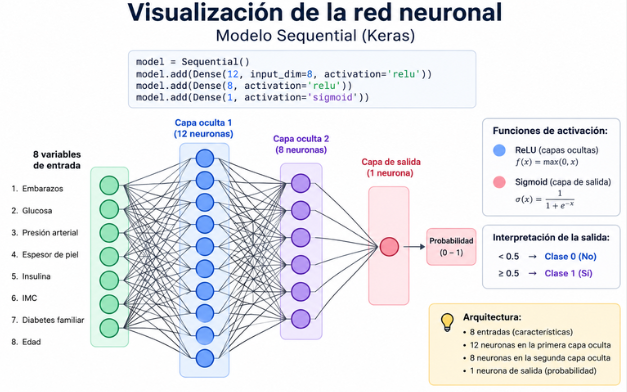


In [6]:

model = Sequential()

# Capa de entrada + capa oculta
model.add(Dense(12,
                input_dim=8,
                activation='relu'))

# Segunda capa oculta
model.add(Dense(8,
                activation='relu'))

# Capa de salida
model.add(Dense(1,
                activation='sigmoid'))



/home/meme/Documentos/9no/ExtraccionDB/Database_Knowledge_Extraction/.venv/lib64/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1786039765.884651   65433 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


**Compilar el modelo**

In [ ]:
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Compila modelo  loos -> que tan mal lo hace, optimizer -> como se va a optimizar, metrics -> que metricas se van a usar

Entrenamiento de la red

In [ ]:
historial = model.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=10,
    validation_split=0.20,
    verbose=1
)

# Entrena utilizando X_train y y_train, repite el proceso 150 veces, procesa 10 datos a la vez, reserva el 20% para validar su aprendizaje

Epoch 1/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4359 - loss: 0.7147 - val_accuracy: 0.5926 - val_loss: 0.6741
Epoch 2/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5991 - loss: 0.6604 - val_accuracy: 0.6667 - val_loss: 0.6425
Epoch 3/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6620 - loss: 0.6261 - val_accuracy: 0.6574 - val_loss: 0.6215
Epoch 4/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6573 - loss: 0.6008 - val_accuracy: 0.6389 - val_loss: 0.6034
Epoch 5/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6620 - loss: 0.5786 - val_accuracy: 0.6389 - val_loss: 0.5848
Epoch 6/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6667 - loss: 0.5605 - val_accuracy: 0.6481 - val_loss: 0.5667
Epoch 7/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6690 - loss: 0.5442 - val_accuracy: 0.6759 - val_loss: 0.5502
Epoch 8/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6737 - loss: 0.5307 - val_accuracy: 0.6852 - v

**Evaluación y predicciones del modelo**


Precisión en prueba: 72.73%
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

Matriz de confusión
[[121  30]
 [ 33  47]]


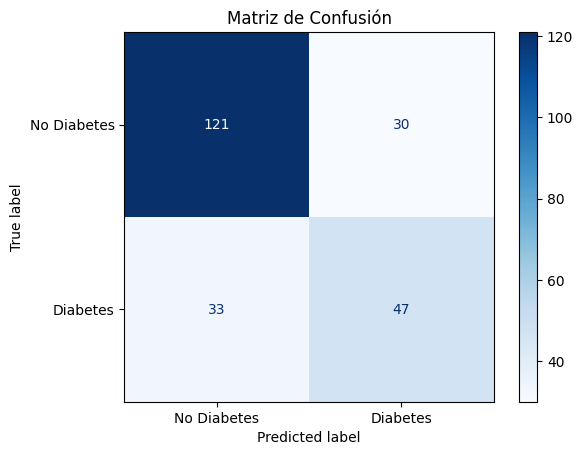


Tasa de aciertos (Accuracy): 72.73%
Tasa de errores: 27.27%

Reporte de clasificación
              precision    recall  f1-score   support

 No Diabetes       0.79      0.80      0.79       151
    Diabetes       0.61      0.59      0.60        80

    accuracy                           0.73       231
   macro avg       0.70      0.69      0.70       231
weighted avg       0.72      0.73      0.73       231



In [9]:

# Evaluación del modelo
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("\nPrecisión en prueba: {:.2f}%".format(accuracy * 100))


# Predicciones

probabilidades = model.predict(X_test)

# Convertir probabilidades a clases (0 o 1)
y_pred = (probabilidades > 0.5).astype(int)


# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

print("\nMatriz de confusión")
print(cm)

# Mostrar la matriz gráficamente
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot(cmap="Blues")
plt.title("Matriz de Confusión")
plt.show()

# Exactitud (Accuracy)
accuracy = accuracy_score(y_test, y_pred)

print("\nTasa de aciertos (Accuracy): {:.2f}%".format(accuracy*100))
print("Tasa de errores: {:.2f}%".format((1-accuracy)*100))


# Reporte de clasificación
print("\nReporte de clasificación")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"]
))

Tuvo una precision de 72.73% de precision esto quiere decir que tan solo un ~27% de error, sin embargo considero que puede mejorar, se muestra la matriz de confusion en el cual dice que hubo - Verdaderos negativos (TN) = 121 - Falsos positivos (FP) = 30 -Falsos negativos (FN) = 33 -Verdaderos positivos (TP) = 47  lo cual significa;
121 personas sin diabetes fueron clasificadas correctamente como No Diabetes.
30 personas sin diabetes fueron clasificadas incorrectamente como Diabetes.
33 personas con diabetes fueron clasificadas incorrectamente como No Diabetes.
47 personas con diabetes fueron clasificadas correctamente como Diabetes.
Por lo tanto quiere decir que el modelo predice mejor cuando una persona no tiene diabetes con un recall de 0.80 mientras que cuando una persona tiene diabtetes tiene un recall de 0.59